# Analyzing Datasets in this notebook

- Basic info & missing values
- Target distribution + time series plot
- Energy consumption by Hour / Day of Week
- Correlation heatmap
- Feature vs Target correlation
- Temperature & Humidity trends
- Outlier analysis

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

### 1. Basic info & missing values

In [2]:
RAW_DATA_PATH = "../data/raw/energy_data_set.csv"

In [3]:
# Load data set
df = pd.read_csv(RAW_DATA_PATH)
df.head(10)

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.890000,47.596667,19.20,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.500000,92.000000,7.000000,63.000000,5.300000,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.890000,46.693333,19.20,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.600000,92.000000,6.666667,59.166667,5.200000,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.890000,46.300000,19.20,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.700000,92.000000,6.333333,55.333333,5.100000,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.890000,46.066667,19.20,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.800000,92.000000,6.000000,51.500000,5.000000,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.890000,46.333333,19.20,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.900000,92.000000,5.666667,47.666667,4.900000,10.084097,10.084097
5,2016-01-11 17:50:00,50,40,19.890000,46.026667,19.20,44.500000,19.79,44.933333,18.890000,...,17.000000,45.29,6.016667,734.000000,92.000000,5.333333,43.833333,4.800000,44.919484,44.919484
6,2016-01-11 18:00:00,60,50,19.890000,45.766667,19.20,44.500000,19.79,44.900000,18.890000,...,17.000000,45.29,5.900000,734.100000,92.000000,5.000000,40.000000,4.700000,47.233763,47.233763
7,2016-01-11 18:10:00,60,50,19.856667,45.560000,19.20,44.500000,19.73,44.900000,18.890000,...,17.000000,45.29,5.916667,734.166667,91.833333,5.166667,40.000000,4.683333,33.039890,33.039890
8,2016-01-11 18:20:00,60,40,19.790000,45.597500,19.20,44.433333,19.73,44.790000,18.890000,...,17.000000,45.29,5.933333,734.233333,91.666667,5.333333,40.000000,4.666667,31.455702,31.455702
9,2016-01-11 18:30:00,70,40,19.856667,46.090000,19.23,44.400000,19.79,44.863333,18.890000,...,17.000000,45.29,5.950000,734.300000,91.500000,5.500000,40.000000,4.650000,3.089314,3.089314


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  str    
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null  float64
 19  T9           19

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Appliances,19735.0,97.694958,102.524891,10.000000,50.000000,60.000000,100.000000,1080.000000
lights,19735.0,3.801875,7.935988,0.000000,0.000000,0.000000,0.000000,70.000000
T1,19735.0,21.686571,1.606066,16.790000,20.760000,21.600000,22.600000,26.260000
RH_1,19735.0,40.259739,3.979299,27.023333,37.333333,39.656667,43.066667,63.360000
T2,19735.0,20.341219,2.192974,16.100000,18.790000,20.000000,21.500000,29.856667
RH_2,19735.0,40.420420,4.069813,20.463333,37.900000,40.500000,43.260000,56.026667
T3,19735.0,22.267611,2.006111,17.200000,20.790000,22.100000,23.290000,29.236000
RH_3,19735.0,39.242500,3.254576,28.766667,36.900000,38.530000,41.760000,50.163333
T4,19735.0,20.855335,2.042884,15.100000,19.530000,20.666667,22.100000,26.200000
RH_4,19735.0,39.026904,4.341321,27.660000,35.530000,38.400000,42.156667,51.090000


In [6]:
df.isnull().sum()

date           0
Appliances     0
lights         0
T1             0
RH_1           0
T2             0
RH_2           0
T3             0
RH_3           0
T4             0
RH_4           0
T5             0
RH_5           0
T6             0
RH_6           0
T7             0
RH_7           0
T8             0
RH_8           0
T9             0
RH_9           0
T_out          0
Press_mm_hg    0
RH_out         0
Windspeed      0
Visibility     0
Tdewpoint      0
rv1            0
rv2            0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
# Convert Date time index

df['date'] = pd.to_datetime(df['date'])
df = df.set_index('date')
df = df.sort_index()

### 2. Visualizing Trends in Energy Consumption

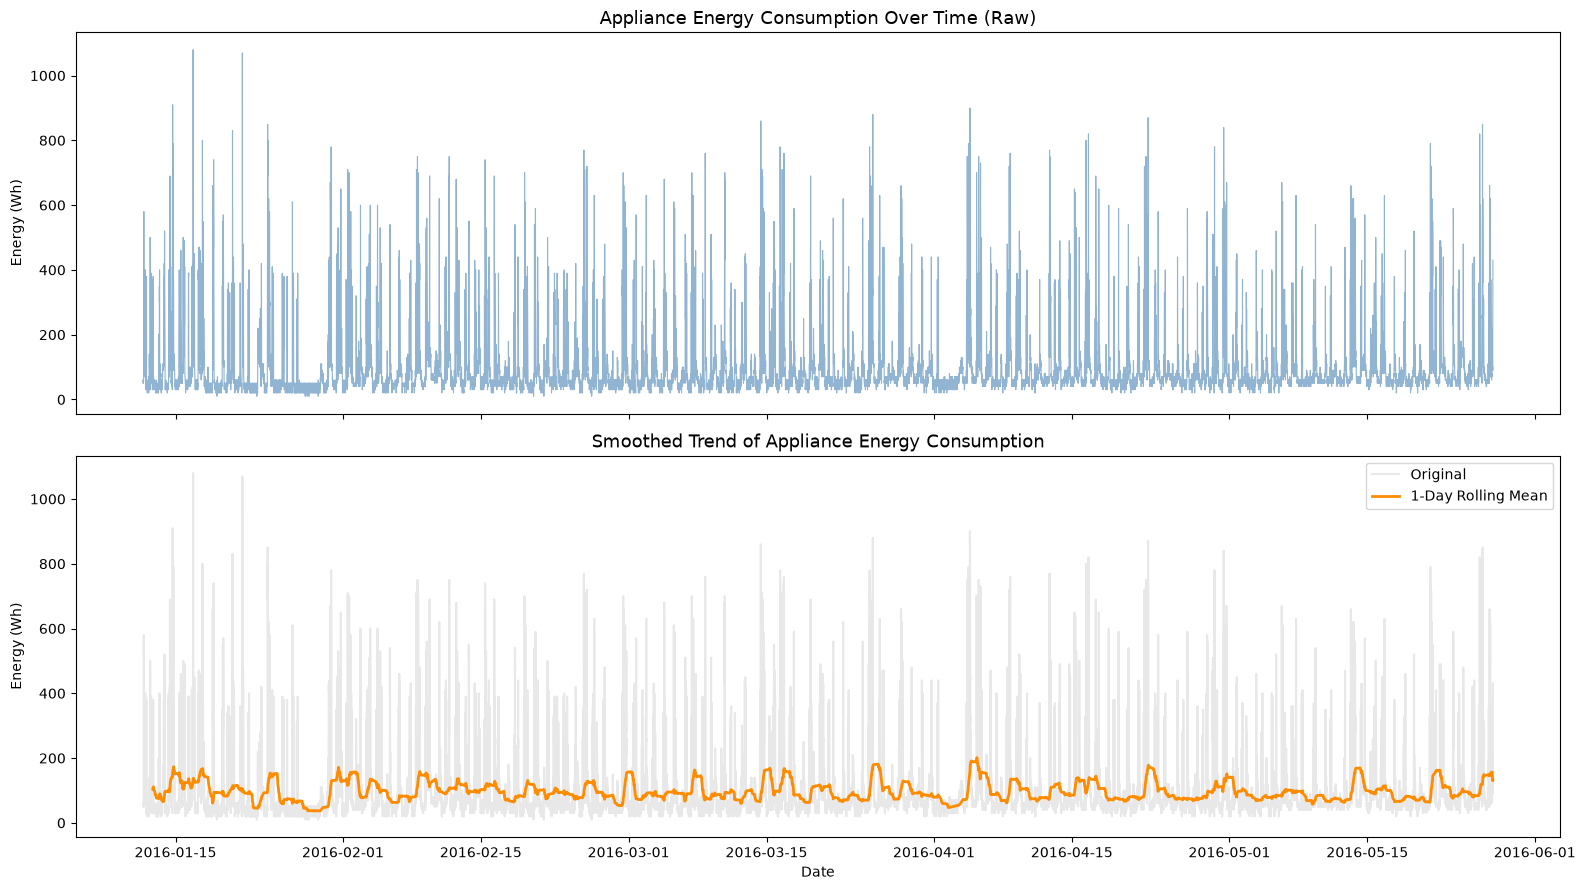

In [9]:
# Trend Visualization
fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

# Raw time series
axes[0].plot(df.index, df['Appliances'], color='steelblue', alpha=0.6, linewidth=0.8)
axes[0].set_title("Appliance Energy Consumption Over Time (Raw)", fontsize=13)
axes[0].set_ylabel("Energy (Wh)")

# Smoothed trend (1-day rolling mean = 144 points)
rolling_mean = df['Appliances'].rolling(window=144).mean()
axes[1].plot(df.index, df['Appliances'], color='lightgray', alpha=0.5, label='Original')
axes[1].plot(df.index, rolling_mean, color='darkorange', linewidth=2, label='1-Day Rolling Mean')
axes[1].set_title("Smoothed Trend of Appliance Energy Consumption", fontsize=13)
axes[1].set_ylabel("Energy (Wh)")
axes[1].legend()

plt.xlabel("Date")
plt.tight_layout()
plt.show()

### 3. Seasonal Patterns – Daily Seasonality

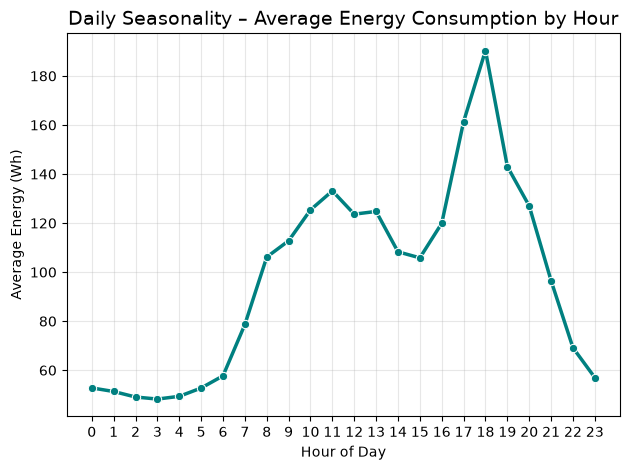

In [10]:

# Daily Seasonality (by plt.figure(figsize=(12, 5))

hourly_avg = df.groupby(df.index.hour)['Appliances'].mean()

sns.lineplot(x=hourly_avg.index, y=hourly_avg.values, marker='o', color='teal', linewidth=2.5)
plt.title("Daily Seasonality – Average Energy Consumption by Hour", fontsize=14)
plt.xlabel("Hour of Day")
plt.ylabel("Average Energy (Wh)")
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 4. Seasonal Patterns – Weekly Seasonality

C:\Users\naduk\AppData\Local\Temp\ipykernel_11920\2752619475.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=daily_avg.index, y=daily_avg.values, palette="viridis")


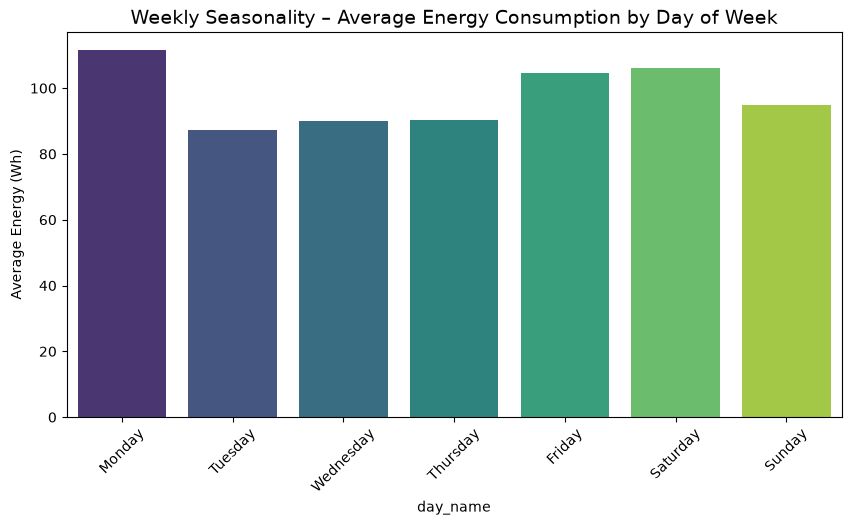

In [11]:
# Weekly Seasonality (by Day of Week)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df['day_name'] = df.index.day_name()

daily_avg = df.groupby('day_name')['Appliances'].mean().reindex(day_order)

plt.figure(figsize=(10, 5))
sns.barplot(x=daily_avg.index, y=daily_avg.values, palette="viridis")
plt.title("Weekly Seasonality – Average Energy Consumption by Day of Week", fontsize=14)
plt.ylabel("Average Energy (Wh)")
plt.xticks(rotation=45)
plt.show()

### 5. Combined Seasonal Pattern (Heatmap)

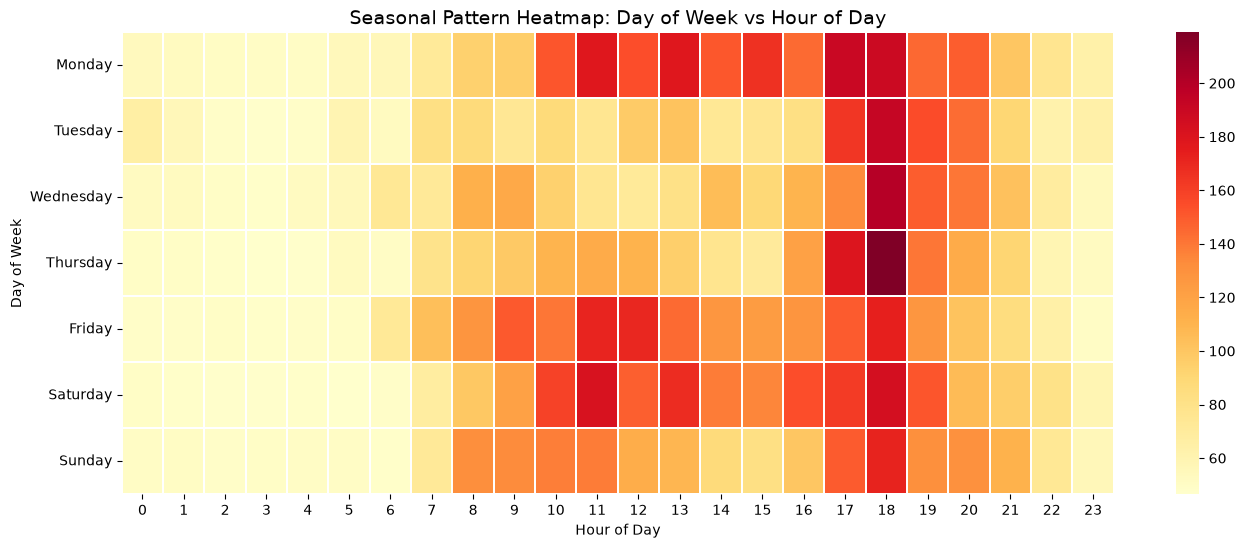

In [12]:
# Heatmap: Day of Week vs Hour
pivot = df.pivot_table(values='Appliances',
                       index=df.index.day_name(),
                       columns=df.index.hour,
                       aggfunc='mean')
pivot = pivot.reindex(day_order)

plt.figure(figsize=(16, 6))
sns.heatmap(pivot, cmap="YlOrRd", linewidths=0.3)
plt.title("Seasonal Pattern Heatmap: Day of Week vs Hour of Day", fontsize=14)
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")
plt.show()

### 6. Correlation Analysis

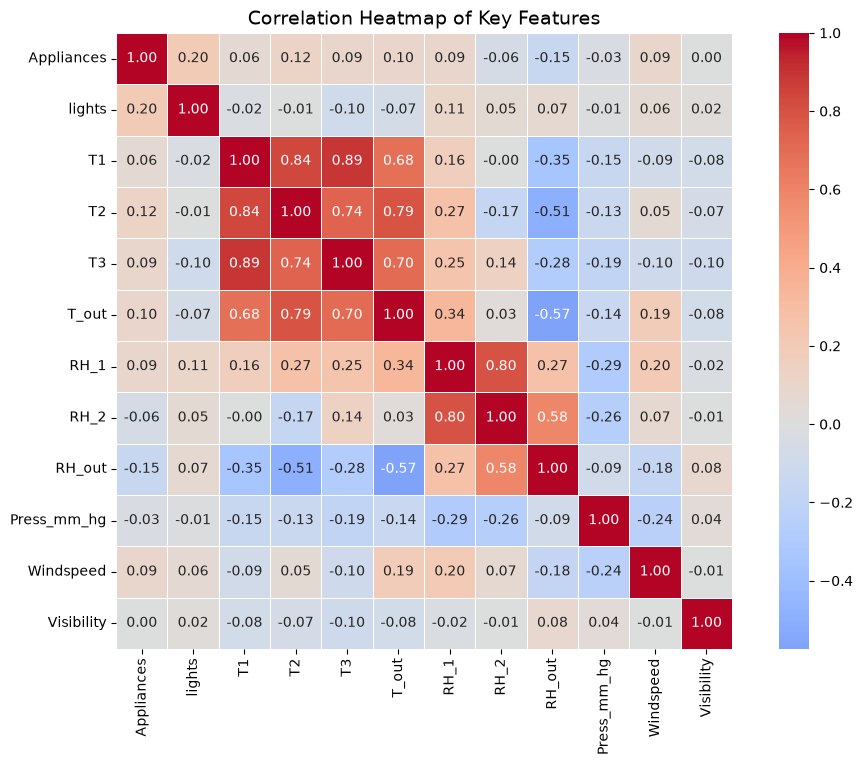

Correlation with Appliances:
Appliances     1.000000
lights         0.197278
T2             0.120073
T6             0.117638
T_out          0.099155
Windspeed      0.087122
RH_1           0.086031
T3             0.085060
T1             0.055447
T4             0.040281
T8             0.039572
RH_3           0.036292
T7             0.025801
T5             0.019760
RH_4           0.016965
Tdewpoint      0.015353
T9             0.010010
RH_5           0.006955
Visibility     0.000230
rv1           -0.011145
rv2           -0.011145
Press_mm_hg   -0.034885
RH_9          -0.051462
RH_7          -0.055642
RH_2          -0.060465
RH_6          -0.083178
RH_8          -0.094039
RH_out        -0.152282
Name: Appliances, dtype: float64


In [13]:
# Correlation Heatmap
important_cols = ['Appliances', 'lights', 'T1', 'T2', 'T3', 'T_out',
                  'RH_1', 'RH_2', 'RH_out', 'Press_mm_hg', 'Windspeed', 'Visibility']

plt.figure(figsize=(12, 8))
sns.heatmap(df[important_cols].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, square=True, linewidths=0.5)
plt.title("Correlation Heatmap of Key Features", fontsize=14)
plt.show()

# Correlation with target
print("Correlation with Appliances:")
print(df.corr(numeric_only=True)['Appliances'].sort_values(ascending=False))

### 7. Distribution and Outliers (Box Plots)

C:\Users\naduk\AppData\Local\Temp\ipykernel_11920\233483948.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df.index.hour, y=df['Appliances'], palette="Set2")


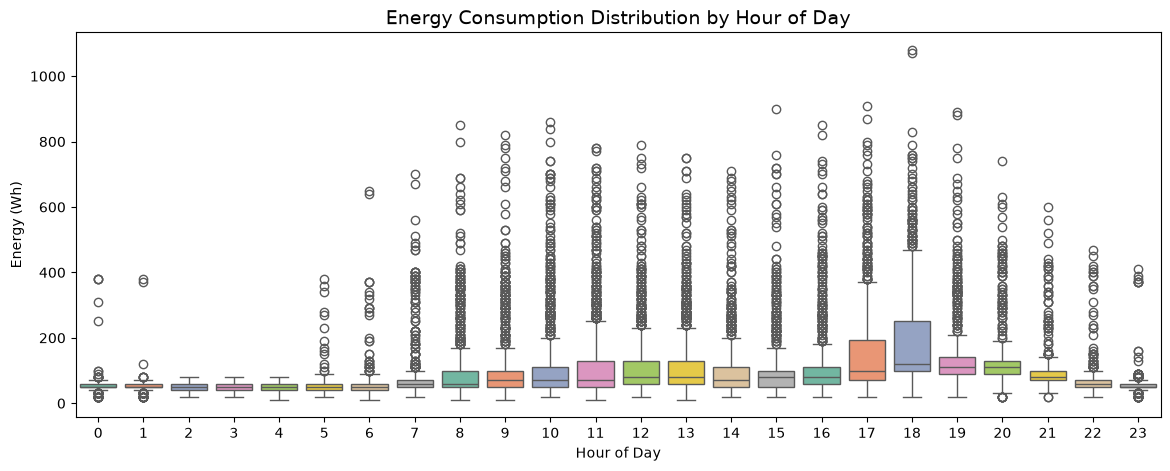

In [14]:
# Boxplot by Hour
plt.figure(figsize=(14, 5))
sns.boxplot(x=df.index.hour, y=df['Appliances'], palette="Set2")
plt.title("Energy Consumption Distribution by Hour of Day", fontsize=14)
plt.xlabel("Hour of Day")
plt.ylabel("Energy (Wh)")
plt.show()